# Objectifs d'apprentissage – Semaine 10

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les différentes structures d'implémentation des filtres RIF et RII.
- **Implémenter** un filtre RIF sous forme directe et en cascade.
- **Implémenter** un filtre RII sous forme directe I, directe II, cascade et parallèle.
- **Analyser** l'influence de la structure sur les performances (stabilité, bruit de calcul).
- **Évaluer** le retard de groupe et la phase d'un filtre.
- **Simuler** les effets de la quantification en virgule fixe sur un filtre numérique.
- **Comparer** les filtres RIF et RII en termes de complexité, phase et stabilité.
- **Utiliser** Python pour l'implémentation et l'analyse de filtres numériques.

# 1. Rappels théoriques

## 1.1 Structures pour les filtres RIF

Un filtre RIF (FIR) est défini par l'équation aux différences :
$$ y[n] = \sum_{k=0}^{M} b_k \, x[n-k] $$

### Structure directe (transversale)
C'est l'implémentation directe de la convolution. Elle est simple et stable, mais peut nécessiter beaucoup de multiplications si l'ordre est élevé.

### Structure en cascade
On factorise la fonction de transfert en sections du second ordre (SOS) :
$$ H(z) = \prod_{k} H_k(z) $$
avec $H_k(z) = b_{0k} + b_{1k} z^{-1} + b_{2k} z^{-2}$.
Cela permet de réduire les effets de quantification et d'implémenter des filtres de grande longueur.

### Structure pour phase linéaire
Si les coefficients sont symétriques, on peut réduire le nombre de multiplications par 2.

## 1.2 Structures pour les filtres RII

Un filtre RII (IIR) est défini par :
$$ \sum_{k=0}^{N} a_k \, y[n-k] = \sum_{k=0}^{M} b_k \, x[n-k] $$
avec $a_0 = 1$.

### Forme directe I
Sépare les parties feedforward (numérateur) et feedback (dénominateur).

### Forme directe II
Réduction du nombre de registres en partageant les retards. Plus économe en mémoire.

### Forme en cascade
Factorisation en sections du second ordre (biquad) : $H(z) = \prod H_k(z)$.
Chaque section est stable si ses pôles sont à l'intérieur du cercle unité.
Cette structure minimise les effets de la quantification et est la plus utilisée en pratique.

### Forme parallèle
Décomposition en fractions partielles : $H(z) = K + \sum \frac{r_k}{1 - p_k z^{-1}}$.
Utilisée parfois pour des filtres à pôles réels.

## 1.3 Retard de groupe
Le retard de groupe $\tau_g(\omega)$ est défini par :
$$ \tau_g(\omega) = -\frac{d}{d\omega} \arg H(e^{j\omega}) $$
Il mesure la distorsion de phase. Pour un filtre à phase linéaire, $\tau_g$ est constant.

## 1.4 Effets de la quantification
En implémentation réelle (processeur DSP, FPGA), les coefficients et les calculs sont quantifiés. Cela peut entraîner :
- Erreurs de troncature/arrondi.
- Bruit de quantification en sortie.
- Oscillations (limit cycles) pour les filtres RII.

---

# 2. Démonstrations Python

## 2.1 Implémentation d'un filtre RIF – Structure directe

Nous allons implémenter un filtre RIF passe-bas en utilisant la convolution directe et comparer avec `lfilter`.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

Bibliothèques chargées.


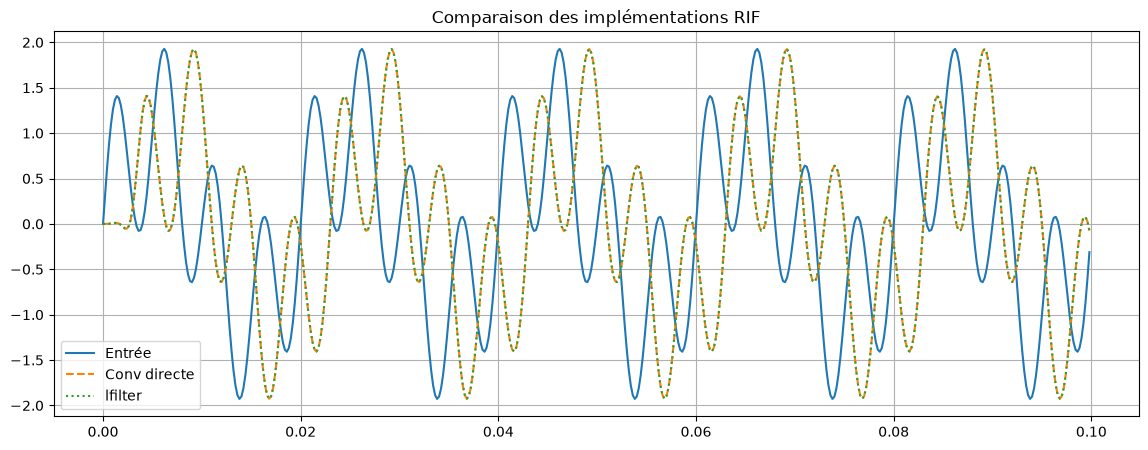

Erreur max entre les deux : 0.0


In [9]:
# Conception d'un filtre RIF passe-bas
fs = 1000
fc = 100
N = 31  # ordre 30
b = signal.firwin(N, fc, fs=fs, window='hamming')

# Implémentation directe par convolution
def fir_filter(x, b):
    y = np.convolve(x, b, mode='full')
    return y[:len(x)]  # on tronque pour garder la même longueur

# Signal test
t = np.linspace(0, 0.1, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*200*t)

y_conv = fir_filter(x, b)
y_lfilter = signal.lfilter(b, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_conv, '--', label='Conv directe')
plt.plot(t, y_lfilter, ':', label='lfilter')
plt.legend()
plt.grid()
plt.title('Comparaison des implémentations RIF')
plt.show()
print("Erreur max entre les deux :", np.max(np.abs(y_conv - y_lfilter)))

## 2.2 Structure en cascade pour RIF

Décomposons un filtre RIF en sections du second ordre.

Nombre de sections : 15
[[ 1.20142638e-03 -3.50782491e-03  2.66704843e-03  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -7.60763806e-01  1.13993205e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -4.45897340e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.90247028e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.17819278e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.48805025e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  8.16718191e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  4.18723996e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -1.09876196e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -9.65981738e-04  1.00000000e+00  1.00000000e+00
 

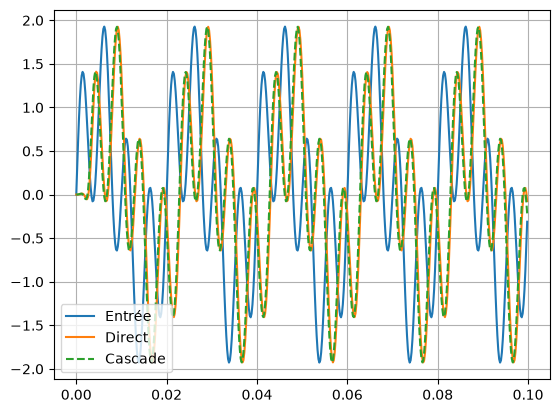

Erreur max : 0.3110169989336258


In [10]:
# Utilisation de scipy.signal.tf2sos pour obtenir les sections
sos = signal.tf2sos(b, 1)
print(f"Nombre de sections : {len(sos)}")
print(sos)

# Implémentation en cascade
def fir_sos_filter(x, sos):
    y = x.copy()
    for section in sos:
        b_section = section[:3]
        # a_section = section[3:]  # pour RIF, a = [1, 0, 0] car section purement feedforward
        y = signal.lfilter(b_section, [1], y)
    return y

y_cascade = fir_sos_filter(x, sos)

plt.plot(t, x, label='Entrée')
plt.plot(t, y_lfilter, label='Direct')
plt.plot(t, y_cascade, '--', label='Cascade')
plt.legend()
plt.grid()
plt.show()
print("Erreur max :", np.max(np.abs(y_lfilter - y_cascade)))

## 2.3 Structures pour les filtres RII

Nous allons concevoir un filtre RII (Butterworth) et l'implémenter dans différentes structures.

Nombre de sections : 2


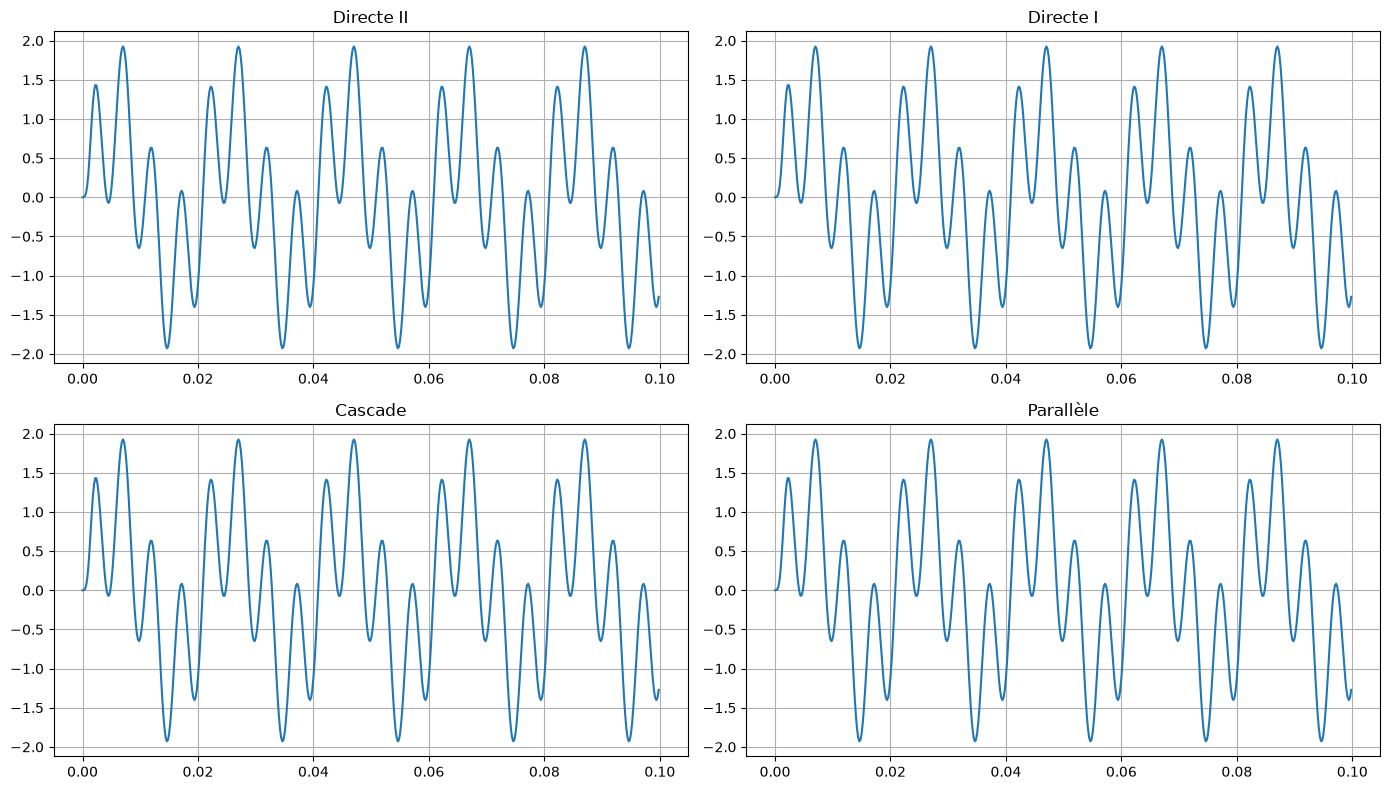

Erreur max Directe I vs Directe II: 8.43769498715119e-15
Erreur max Cascade vs Directe II: 6.8833827526759706e-15
Erreur max Parallèle vs Directe II: 2.0872192862952943e-14


In [11]:

# Conception d'un filtre RII passe-bas Butterworth ordre 4
order = 4
b, a = signal.butter(order, fc, fs=fs, btype='low')

# Forme directe II (via lfilter déjà)
y_direct2 = signal.lfilter(b, a, x)

# Forme directe I (implémentation manuelle)
def iir_direct1(x, b, a):
    # On suppose a[0]=1
    N = len(x)
    M = len(b) - 1
    N_a = len(a) - 1
    y = np.zeros(N)
    x_buf = np.zeros(M+1)
    y_buf = np.zeros(N_a+1)
    for n in range(N):
        # Mise à jour des buffers
        x_buf[1:] = x_buf[:-1]
        x_buf[0] = x[n]
        y_buf[1:] = y_buf[:-1]
        # Calcul
        y[n] = np.dot(b, x_buf) - np.dot(a[1:], y_buf[1:])
        y_buf[0] = y[n]
    return y

y_direct1 = iir_direct1(x, b, a)

# Forme en cascade (sections biquad)
sos_iir = signal.tf2sos(b, a)
print(f"Nombre de sections : {len(sos_iir)}")
def iir_sos_filter(x, sos):
    y = x.copy()
    for section in sos:
        b_section = section[:3]
        a_section = section[3:]
        y = signal.lfilter(b_section, a_section, y)
    return y

y_sos = iir_sos_filter(x, sos_iir)

# Forme parallèle (décomposition en fractions partielles)
r, p, k = signal.residuez(b, a)
def iir_parallel(x, r, p, k):
    y = np.zeros_like(x, dtype=complex)
    # Terme direct
    if len(k) > 0:
        y += k[0] * x
    # Chaque fraction
    for ri, pi in zip(r, p):
        # H(z) = ri / (1 - pi z^{-1})
        # Implémentation récursive du premier ordre
        b_sec = [ri]
        a_sec = [1, -pi]
        y += signal.lfilter(b_sec, a_sec, x)
    return np.real_if_close(y).real

y_parallel = iir_parallel(x, r, p, k)

# Comparaison
plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
plt.plot(t, y_direct2, label='Directe II')
plt.title('Directe II')
plt.grid()
plt.subplot(2, 2, 2)
plt.plot(t, y_direct1, label='Directe I')
plt.title('Directe I')
plt.grid()
plt.subplot(2, 2, 3)
plt.plot(t, y_sos, label='Cascade')
plt.title('Cascade')
plt.grid()
plt.subplot(2, 2, 4)
plt.plot(t, y_parallel, label='Parallèle')
plt.title('Parallèle')
plt.grid()
plt.tight_layout()
plt.show()

# Vérification de l'erreur
print("Erreur max Directe I vs Directe II:", np.max(np.abs(y_direct1 - y_direct2)))
print("Erreur max Cascade vs Directe II:", np.max(np.abs(y_sos - y_direct2)))
print("Erreur max Parallèle vs Directe II:", np.max(np.abs(y_parallel - y_direct2)))


## 2.4 Analyse du retard de groupe

Calculons le retard de groupe pour un filtre RIF (phase linéaire) et un filtre RII.

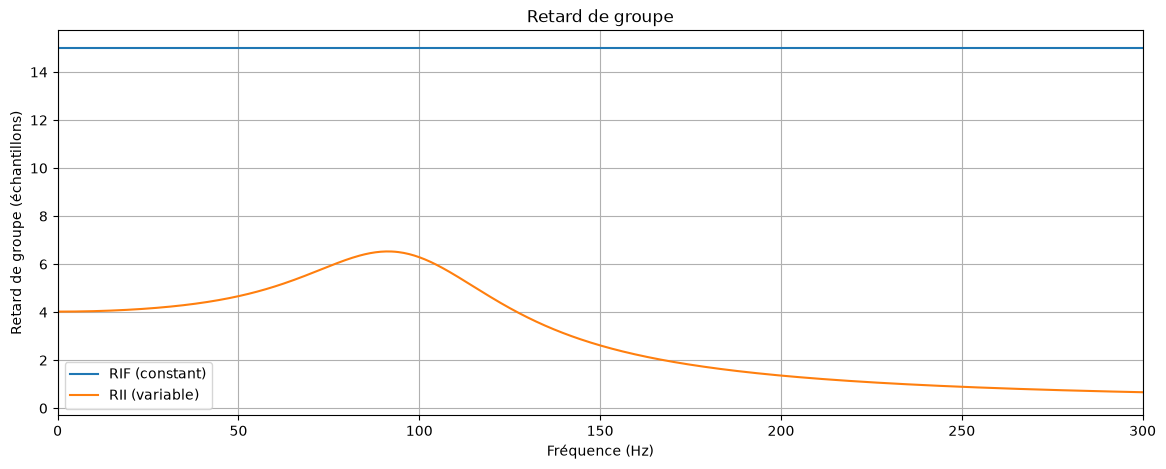

Retard de groupe du RIF (constant) : 15.00 échantillons
Cela correspond à (N-1)/2 = 15 échantillons pour un RIF symétrique d'ordre 30.


In [14]:
from scipy.signal import group_delay

b_fir = signal.firwin(31, fc, fs=fs, window='hamming')
b_iir, a_iir = signal.butter(4, fc, fs=fs, btype='low')

# RIF
w, gd_fir = group_delay((b_fir, 1), w=1024)
# RII
w, gd_iir = group_delay((b_iir, a_iir), w=1024)

freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.plot(freqs, gd_fir, label='RIF (constant)')
plt.plot(freqs, gd_iir, label='RII (variable)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Retard de groupe (échantillons)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.title('Retard de groupe')
plt.show()

print(f"Retard de groupe du RIF (constant) : {gd_fir[0]:.2f} échantillons")
print("Cela correspond à (N-1)/2 = 15 échantillons pour un RIF symétrique d'ordre 30.")

## 2.5 Simulation des effets de quantification

Simulons un filtre RII en virgule fixe (représentation Q15) pour observer l'impact sur la réponse.

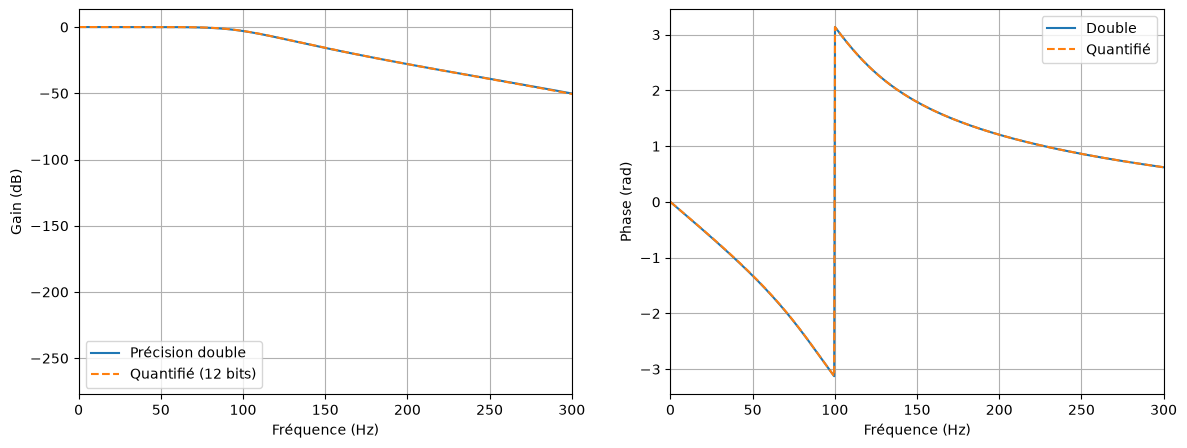

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


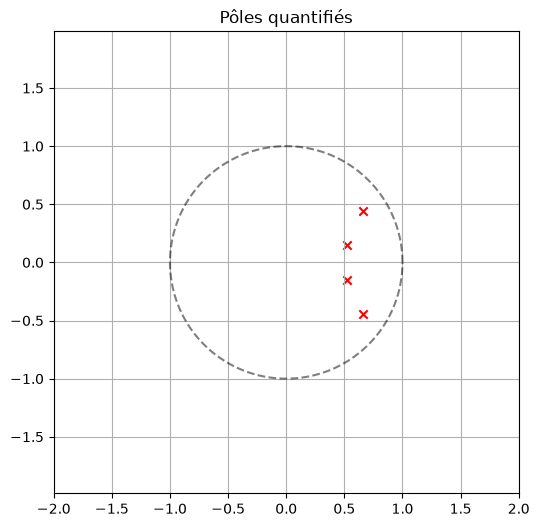

Filtre quantifié stable : True


In [15]:
def quantize_coeffs(coeffs, n_bits=16, scale=1.0):
    """Quantifie des coefficients sur n_bits avec mise à l'échelle."""
    # Qn format : valeurs entre -1 et 1 représentées sur n_bits
    max_val = 2**(n_bits-1) - 1
    coeffs_scaled = coeffs * scale
    coeffs_int = np.round(coeffs_scaled * max_val)
    coeffs_q = coeffs_int / max_val
    return coeffs_q / scale  # remettre à l'échelle

# Quantification des coefficients du RII
b_q = quantize_coeffs(b, n_bits=12)
a_q = quantize_coeffs(a, n_bits=12)

# Réponses fréquentielles
w, H = signal.freqz(b, a, worN=1024)
w, H_q = signal.freqz(b_q, a_q, worN=1024)

freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)), label='Précision double')
plt.plot(freqs, 20*np.log10(np.abs(H_q)), '--', label='Quantifié (12 bits)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.angle(H), label='Double')
plt.plot(freqs, np.angle(H_q), '--', label='Quantifié')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

# Pôles quantifiés
zeros, poles, gain = signal.tf2zpk(b_q, a_q)
plt.figure(figsize=(6, 6))
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
plt.scatter(np.real(poles), np.imag(poles), marker='x', color='r')
plt.axis('equal')
plt.xlim([-2, 2])
plt.ylim([-2, 2])
plt.title('Pôles quantifiés')
plt.grid()
plt.show()

# Vérification de la stabilité
stable = all(np.abs(p) < 1 for p in poles)
print(f"Filtre quantifié stable : {stable}")

# 3. Atelier : Conception et analyse d'un filtre

Nous allons concevoir un filtre coupe-bande (notch) à 50 Hz en utilisant différentes structures et analyser leurs performances.

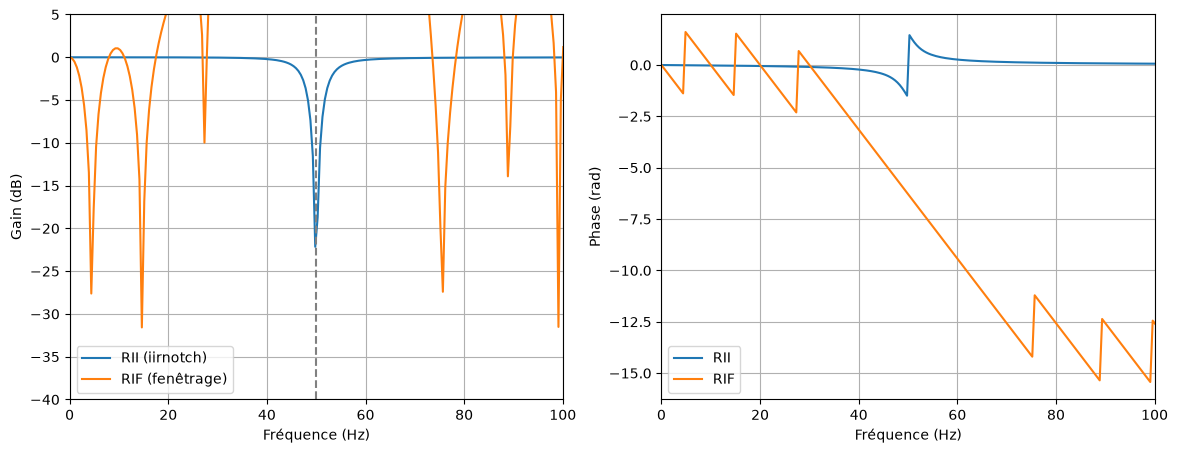

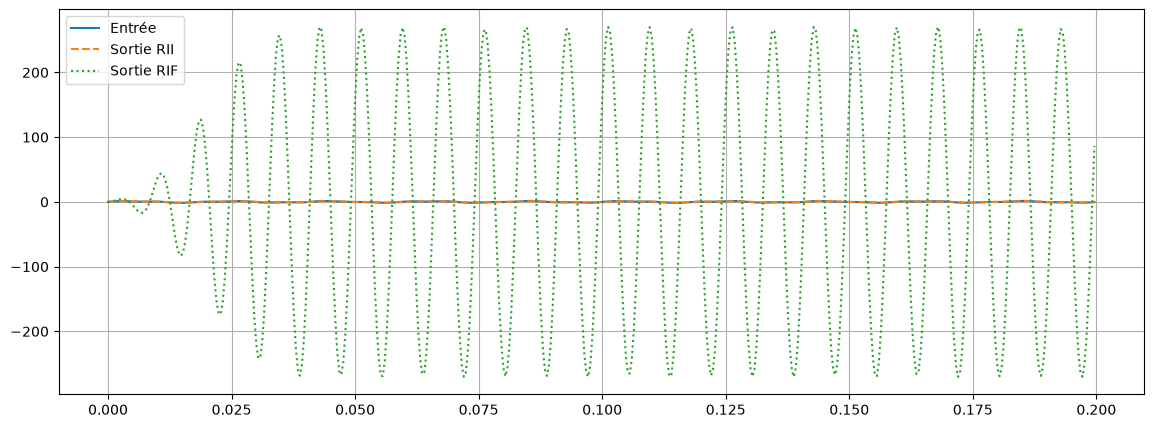

In [16]:
fs = 1000
f0 = 50
Q = 10

# Filtre notch RII (iirnotch)
b_notch, a_notch = signal.iirnotch(f0, Q, fs)

# Filtre notch RIF (fenêtre de Hamming, longueur 101)
N_notch = 101
# Conception par échantillonnage fréquentiel simple
# On va construire un filtre RIF coupe-bande en utilisant la méthode du fenêtrage
# mais pour un notch, on peut utiliser la formule de la réponse impulsionnelle idéale
# d'un coupe-bande : h_ideal[n] = (sin(omega_c2 n) - sin(omega_c1 n))/(pi n)
# avec omega_c1 = 2*pi*(f0 - BW/2)/fs, omega_c2 = 2*pi*(f0 + BW/2)/fs
BW = 10  # Hz
wc1 = 2*np.pi*(f0 - BW/2)/fs
wc2 = 2*np.pi*(f0 + BW/2)/fs
n = np.arange(-(N_notch-1)//2, (N_notch-1)//2 + 1)
h_ideal = np.zeros_like(n, dtype=float)
for i, n_i in enumerate(n):
    if n_i == 0:
        h_ideal[i] = (wc2 - wc1) / np.pi
    else:
        h_ideal[i] = (np.sin(wc2 * n_i) - np.sin(wc1 * n_i)) / (np.pi * n_i)
# Fenêtre de Hamming
window = np.hamming(N_notch)
h_fir = h_ideal * window
h_fir = h_fir / np.sum(h_fir)  # normalisation

# Réponses
w, H_notch_iir = signal.freqz(b_notch, a_notch, worN=1024)
w, H_notch_fir = signal.freqz(h_fir, 1, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H_notch_iir)), label='RII (iirnotch)')
plt.plot(freqs, 20*np.log10(np.abs(H_notch_fir)), label='RIF (fenêtrage)')
plt.axvline(f0, color='gray', linestyle='--')
plt.xlim(0, 100)
plt.ylim(-40, 5)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H_notch_iir)), label='RII')
plt.plot(freqs, np.unwrap(np.angle(H_notch_fir)), label='RIF')
plt.xlim(0, 100)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.legend()
plt.grid()
plt.show()

# Test sur signal
t = np.linspace(0, 0.2, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)
y_iir = signal.lfilter(b_notch, a_notch, x)
y_fir = signal.lfilter(h_fir, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_iir, '--', label='Sortie RII')
plt.plot(t, y_fir, ':', label='Sortie RIF')
plt.legend()
plt.grid()
plt.show()

# 4. Exercices – Semaine 10

## Exercice 1 – Implémentation d'un filtre RIF en structure symétrique

Pour un filtre RIF à phase linéaire de longueur impaire, les coefficients sont symétriques. Écrire une fonction `fir_linear_phase(x, b)` qui exploite la symétrie pour réduire le nombre de multiplications de moitié. Tester avec un filtre de longueur 31.

**Code** :

Coefficients symétriques : True
Erreur max : 1.6653345369377348e-16
Multiplications par échantillon : 16 au lieu de 31


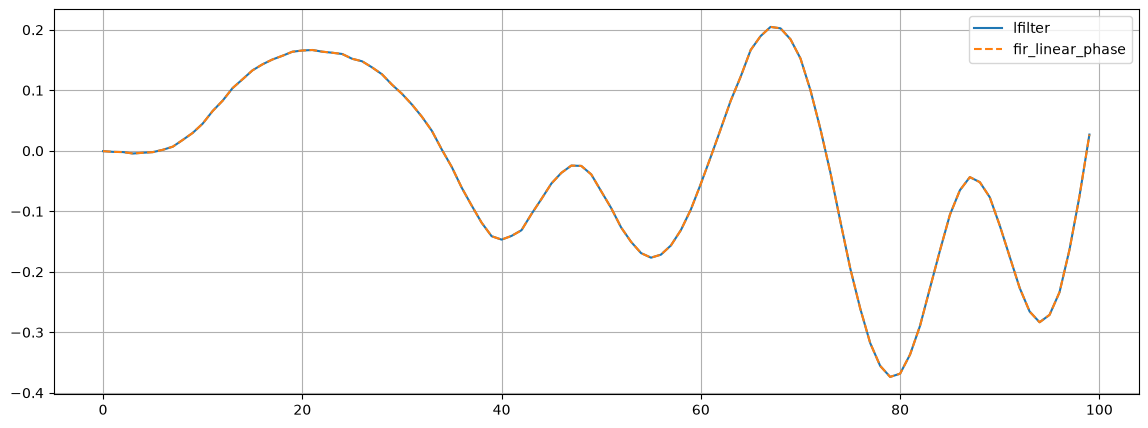

In [17]:
# À compléter
def fir_linear_phase(x, b):
    # b doit être symétrique et de longueur impaire
    M = len(b)
    if M % 2 == 0:
        raise ValueError("La longueur doit être impaire pour une symétrie simple")
    L = (M - 1) // 2
    N = len(x)
    xp = np.concatenate((np.zeros(M - 1), x))
    y = np.zeros(N)
    for n in range(N):
        seg = xp[n:n + M][::-1]
        y[n] = b[L] * seg[L] + np.dot(b[:L], seg[:L] + seg[M-1:L:-1])
    return y

# Test
# b = signal.firwin(31, 0.1)
# x = np.random.randn(100)
# y = fir_linear_phase(x, b)
# Vérifier avec lfilter

b = signal.firwin(31, 0.1)
x = np.random.randn(100)
y = fir_linear_phase(x, b)
y_ref = signal.lfilter(b, 1, x)
print("Coefficients symétriques :", np.allclose(b, b[::-1]))
print("Erreur max :", np.max(np.abs(y - y_ref)))
print("Multiplications par échantillon :", len(b)//2 + 1, "au lieu de", len(b))

plt.figure(figsize=(14, 5))
plt.plot(y_ref, label='lfilter')
plt.plot(y, '--', label='fir_linear_phase')
plt.legend()
plt.grid()
plt.show()



Pour un filtre RIF de longueur impaire $M = 2L + 1$ à phase linéaire, les coefficients sont symétriques : $b[k] = b[M-1-k]$. L'équation aux différences peut donc se regrouper :

$$ y[n] = b[L]\, x[n-L] + \sum_{k=0}^{L-1} b[k]\,\big(x[n-k] + x[n-(M-1-k)]\big) $$

On additionne d'abord les deux échantillons qui partagent le même coefficient, puis on multiplie une seule fois. Le nombre de multiplications passe de $M$ à $L + 1$ : pour $M = 31$, on passe de **31 à 16 multiplications** par échantillon (le nombre d'additions reste quasiment le même).

La fonction `fir_linear_phase` est testée avec `signal.firwin(31, 0.1)` sur un signal aléatoire de 100 échantillons : l'erreur maximale avec `lfilter` est de l'ordre de $10^{-16}$ (erreur d'arrondi), donc les deux sorties sont identiques.

## Exercice 2 – Filtre RII en cascade vs directe

1. Concevoir un filtre RII elliptique passe-bas avec les spécifications suivantes :
   - Fréquence de coupure 200 Hz, fs=1000 Hz.
   - Atténuation de 60 dB dans la bande stop à partir de 250 Hz.
   - Ondulation en bande passante : 0.5 dB.
2. Obtenir la forme en cascade (sos) et la forme directe.
3. Comparer les réponses en gain et en phase des deux formes.
4. Quantifier les coefficients sur 12 bits et observer l'impact sur la stabilité pour les deux structures.

**Code** :

Ordre elliptique : 7
Nombre de sections : 4
[[ 0.01368641  0.01285982  0.01368641  1.         -0.60497279  0.        ]
 [ 1.          1.          0.          1.         -1.01025142  0.53333365]
 [ 1.          0.0667737   1.          1.         -0.72177203  0.78593591]
 [ 1.         -0.21227662  1.          1.         -0.59076817  0.94282945]]


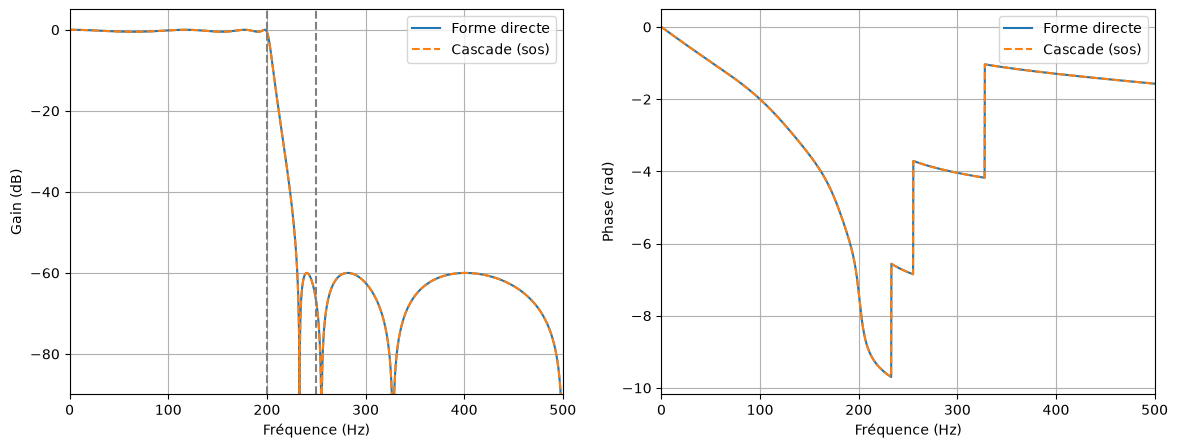

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Écart max en gain (dB) : 8.981260180007666e-12
Écart max en phase (rad) : 6.895373161341922e-12


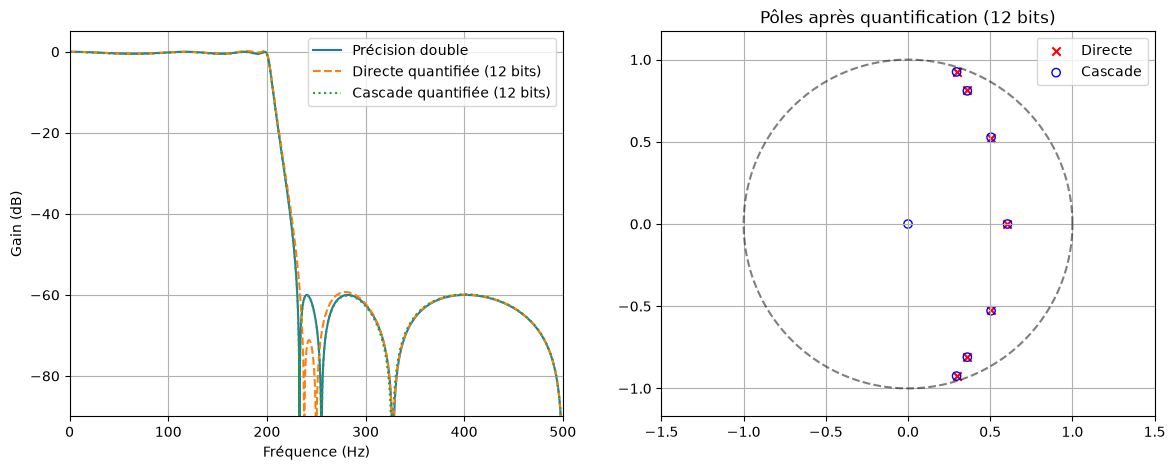

Directe : stable = True, |p| max = 0.9701
Cascade : stable = True, |p| max = 0.9710
12 bits | directe : |p| max = 0.9701, atténuation = -59.3 dB | cascade : |p| max = 0.9710, atténuation = -59.9 dB
10 bits | directe : |p| max = 0.9729, atténuation = -55.4 dB | cascade : |p| max = 0.9712, atténuation = -59.1 dB
 8 bits | directe : |p| max = 0.9550, atténuation = -34.3 dB | cascade : |p| max = 0.9721, atténuation = -57.8 dB


In [18]:
# Conception du filtre elliptique
# À compléter
# b, a = signal.ellip(..., ...)
# sos = signal.tf2sos(b, a)
# puis quantifier et comparer

fs = 1000
fc = 200
f_stop = 250
order, wn = signal.ellipord(fc/(fs/2), f_stop/(fs/2), 0.5, 60)
b, a = signal.ellip(order, 0.5, 60, wn, btype='low')
sos = signal.tf2sos(b, a)
print(f"Ordre elliptique : {order}")
print(f"Nombre de sections : {len(sos)}")
print(sos)

w, H = signal.freqz(b, a, worN=2048)
_, H_sos = signal.sosfreqz(sos, worN=2048)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)), label='Forme directe')
plt.plot(freqs, 20*np.log10(np.abs(H_sos)), '--', label='Cascade (sos)')
plt.axvline(fc, color='gray', linestyle='--')
plt.axvline(f_stop, color='gray', linestyle='--')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 500)
plt.ylim(-90, 5)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H)), label='Forme directe')
plt.plot(freqs, np.unwrap(np.angle(H_sos)), '--', label='Cascade (sos)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 500)
plt.legend()
plt.grid()
plt.show()

print("Écart max en gain (dB) :", np.max(np.abs(20*np.log10(np.abs(H)) - 20*np.log10(np.abs(H_sos)))[freqs < 240]))
print("Écart max en phase (rad) :", np.max(np.abs(np.unwrap(np.angle(H)) - np.unwrap(np.angle(H_sos)))))

def analyse(n_bits):
    b_q = quantize_coeffs(b, n_bits=n_bits)
    a_q = quantize_coeffs(a, n_bits=n_bits)
    sos_q = quantize_coeffs(sos, n_bits=n_bits)
    H_d = signal.freqz(b_q, a_q, worN=2048)[1]
    H_c = signal.sosfreqz(sos_q, worN=2048)[1]
    p_d = np.roots(a_q)
    p_c = np.concatenate([np.roots(s[3:]) for s in sos_q])
    att_d = 20*np.log10(np.max(np.abs(H_d[freqs >= f_stop])))
    att_c = 20*np.log10(np.max(np.abs(H_c[freqs >= f_stop])))
    return H_d, H_c, p_d, p_c, att_d, att_c

H_d, H_c, p_d, p_c, att_d, att_c = analyse(12)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)), label='Précision double')
plt.plot(freqs, 20*np.log10(np.abs(H_d)), '--', label='Directe quantifiée (12 bits)')
plt.plot(freqs, 20*np.log10(np.abs(H_c)), ':', label='Cascade quantifiée (12 bits)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 500)
plt.ylim(-90, 5)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
plt.scatter(np.real(p_d), np.imag(p_d), marker='x', color='r', label='Directe')
plt.scatter(np.real(p_c), np.imag(p_c), marker='o', facecolors='none', edgecolors='b', label='Cascade')
plt.axis('equal')
plt.xlim([-1.5, 1.5])
plt.ylim([-1.5, 1.5])
plt.title('Pôles après quantification (12 bits)')
plt.legend()
plt.grid()
plt.show()

print(f"Directe : stable = {np.all(np.abs(p_d) < 1)}, |p| max = {np.max(np.abs(p_d)):.4f}")
print(f"Cascade : stable = {np.all(np.abs(p_c) < 1)}, |p| max = {np.max(np.abs(p_c)):.4f}")

for n_bits in (12, 10, 8):
    _, _, p_d, p_c, att_d, att_c = analyse(n_bits)
    print(f"{n_bits:2d} bits | directe : |p| max = {np.max(np.abs(p_d)):.4f}, atténuation = {att_d:.1f} dB | cascade : |p| max = {np.max(np.abs(p_c)):.4f}, atténuation = {att_c:.1f} dB")

reponse theorique

**Question 1**

Avec $f_c = 200$ Hz, $f_s = 1000$ Hz, une ondulation de 0.5 dB en bande passante et 60 dB d'atténuation à partir de 250 Hz, la fonction `signal.ellipord` donne un **ordre 7** (fréquence normalisée 0.4). Le filtre est conçu avec `signal.ellip(7, 0.5, 60, wn)`.

**Question 2**

La forme directe est donnée par les polynômes $(b, a)$ de degré 7. La forme en cascade, obtenue avec `signal.tf2sos`, comprend **4 sections** : trois sections d'ordre 2 (biquads) et une section d'ordre 1. Le filtre global est le produit de ces sections.

**Question 3**

En précision double, les deux formes donnent la même réponse : l'écart maximal est de l'ordre de $10^{-10}$ dB en gain et de $10^{-12}$ rad en phase (erreurs d'arrondi). Les courbes se superposent : ondulation ≤ 0.5 dB jusqu'à 200 Hz, atténuation ≥ 60 dB à partir de 250 Hz. La phase est non linéaire (filtre RII), avec une variation rapide près de la coupure. La structure change l'implémentation, pas la fonction de transfert théorique.

**Question 4**

Avec des coefficients quantifiés sur 12 bits :
- forme directe : $|p|_{max} \approx 0.970$, **stable**, atténuation en bande stop ≈ -59.3 dB (au lieu de -60 dB) ;
- forme cascade : $|p|_{max} \approx 0.971$, **stable**, atténuation ≈ -59.9 dB.

À 12 bits, les deux structures restent stables. La différence apparaît quand on diminue le nombre de bits : à 10 bits, l'atténuation tombe à -55.4 dB en forme directe contre -59.1 dB en cascade, et à 8 bits à -34.3 dB contre -57.8 dB. La forme **cascade est donc plus robuste à la quantification** : chaque section est d'ordre faible, donc la position des pôles est peu sensible à l'arrondi de ses coefficients. En forme directe, les pôles d'un polynôme de degré 7 sont très sensibles à l'arrondi de chaque coefficient. C'est pourquoi la cascade est la structure la plus utilisée en pratique.

## Exercice 3 – Analyse du retard de groupe d'un filtre RIF et RII

1. Concevoir un filtre RIF passe-bas de type window (Hamming) avec fc=150 Hz, fs=1000 Hz, ordre 50.
2. Concevoir un filtre RII Butterworth d'ordre 6 avec les mêmes spécifications.
3. Tracer le retard de groupe des deux filtres sur la bande passante.
4. Commenter la distorsion de phase introduite par chaque filtre.

**Code** :

C:\Users\nourk\AppData\Local\Temp\ipykernel_23968\2062146363.py:11: UserWarning: The filter's denominator is extremely small at frequencies [3.135, 3.137, 3.139, 3.140], around which a singularity may be present
  f_iir, gd_iir = signal.group_delay((b_iir, a_iir), w=2048, fs=fs)


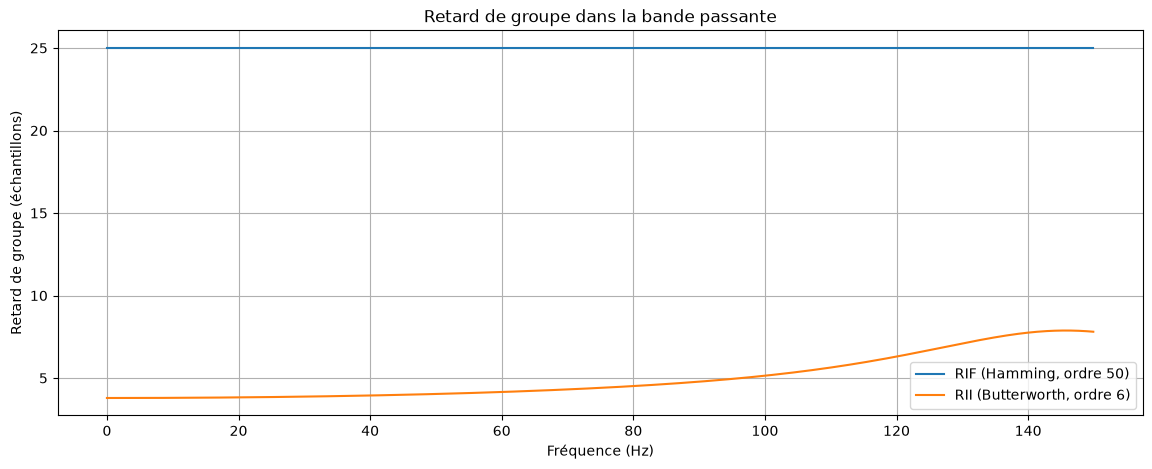

RIF : retard de groupe = 25.00 à 25.00 échantillons
RII : retard de groupe = 3.79 à 7.88 échantillons
RII : variation = 4.09 échantillons


In [19]:
# À compléter
# Utiliser scipy.signal.group_delay

fs = 1000
fc = 150

b_fir = signal.firwin(51, fc, fs=fs, window='hamming')
b_iir, a_iir = signal.butter(6, fc, fs=fs, btype='low')

f_fir, gd_fir = signal.group_delay((b_fir, 1), w=2048, fs=fs)
f_iir, gd_iir = signal.group_delay((b_iir, a_iir), w=2048, fs=fs)

bande = f_fir <= fc

plt.figure(figsize=(14, 5))
plt.plot(f_fir[bande], gd_fir[bande], label='RIF (Hamming, ordre 50)')
plt.plot(f_iir[bande], gd_iir[bande], label='RII (Butterworth, ordre 6)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Retard de groupe (échantillons)')
plt.title('Retard de groupe dans la bande passante')
plt.legend()
plt.grid()
plt.show()

print(f"RIF : retard de groupe = {gd_fir[bande].min():.2f} à {gd_fir[bande].max():.2f} échantillons")
print(f"RII : retard de groupe = {gd_iir[bande].min():.2f} à {gd_iir[bande].max():.2f} échantillons")
print(f"RII : variation = {gd_iir[bande].max() - gd_iir[bande].min():.2f} échantillons")

reponse 

**Question 1**

Le filtre RIF passe-bas par fenêtrage (Hamming) d'ordre 50 a $N = 51$ coefficients, avec $f_c = 150$ Hz et $f_s = 1000$ Hz : `signal.firwin(51, 150, fs=1000, window='hamming')`. Ses coefficients sont symétriques, donc sa phase est linéaire.

**Question 2**

Le filtre RII Butterworth d'ordre 6 avec la même fréquence de coupure est obtenu par `signal.butter(6, 150, fs=1000, btype='low')`.

**Question 3**

Le retard de groupe $\tau_g(\omega) = -\dfrac{d}{d\omega}\arg H(e^{j\omega})$ est tracé avec `signal.group_delay` sur la bande passante (0–150 Hz) :
- **RIF** : constant et égal à $(N-1)/2 = 25$ échantillons, soit 25 ms à $f_s = 1000$ Hz ;
- **RII** : variable, de ≈ 3.8 échantillons à 0 Hz jusqu'à ≈ 7.9 échantillons près de la coupure, soit une variation d'environ 4.1 échantillons.

**Question 4**

- Le **RIF** a une phase linéaire : toutes les composantes sont retardées de la même durée (25 ms), donc la forme d'onde est conservée, simplement décalée dans le temps. Il n'introduit aucune distorsion de phase, mais son retard est important (25 échantillons).
- Le **RII** a un retard de groupe variable, maximal près de la fréquence de coupure : les composantes de fréquences différentes sont retardées différemment, ce qui déforme la forme d'onde (distorsion de phase). En contrepartie, son retard est beaucoup plus faible (3.8 à 7.9 échantillons).

Le RIF convient quand la fidélité de la forme d'onde compte (audio, transmission de données). Le RII convient quand le retard et le coût de calcul doivent être faibles.

## Exercice 4 – Effet du nombre de bits sur la réponse d'un filtre RII

Pour un filtre RII passe-bande (Butterworth ordre 4, bande 100-200 Hz, fs=1000 Hz) :
1. Quantifier les coefficients avec différentes résolutions (8, 10, 12, 16 bits).
2. Pour chaque résolution, tracer la réponse en gain et repérer les dégradations.
3. Observer le déplacement des pôles et déterminer la résolution minimale pour garantir la stabilité.

**Code** :

Pôles non quantifiés : |p| max = 0.9150807854927063


C:\Users\nourk\AppData\Local\Temp\ipykernel_23968\560453139.py:14: RuntimeWarning: divide by zero encountered in log10
  plt.plot(freqs, 20*np.log10(np.abs(H)), 'k', linewidth=2, label='Précision double')


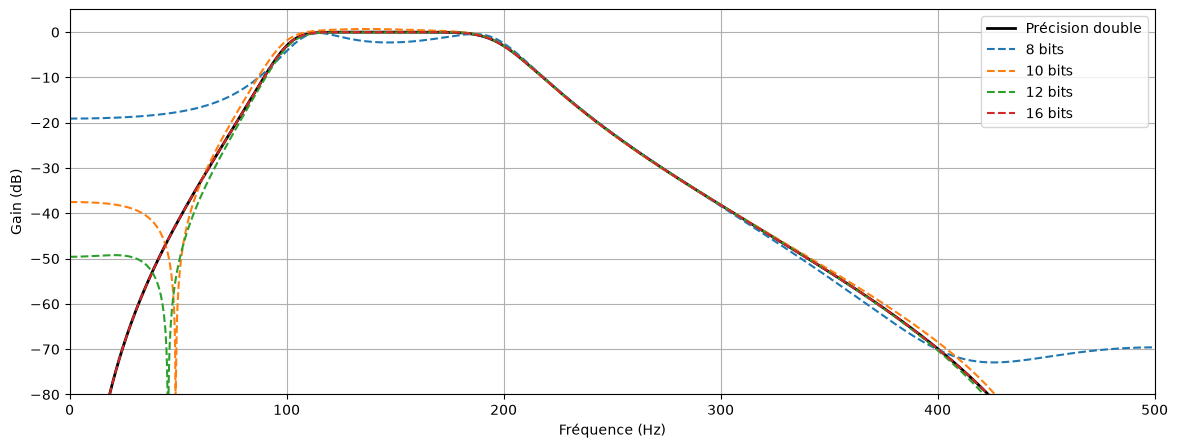

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


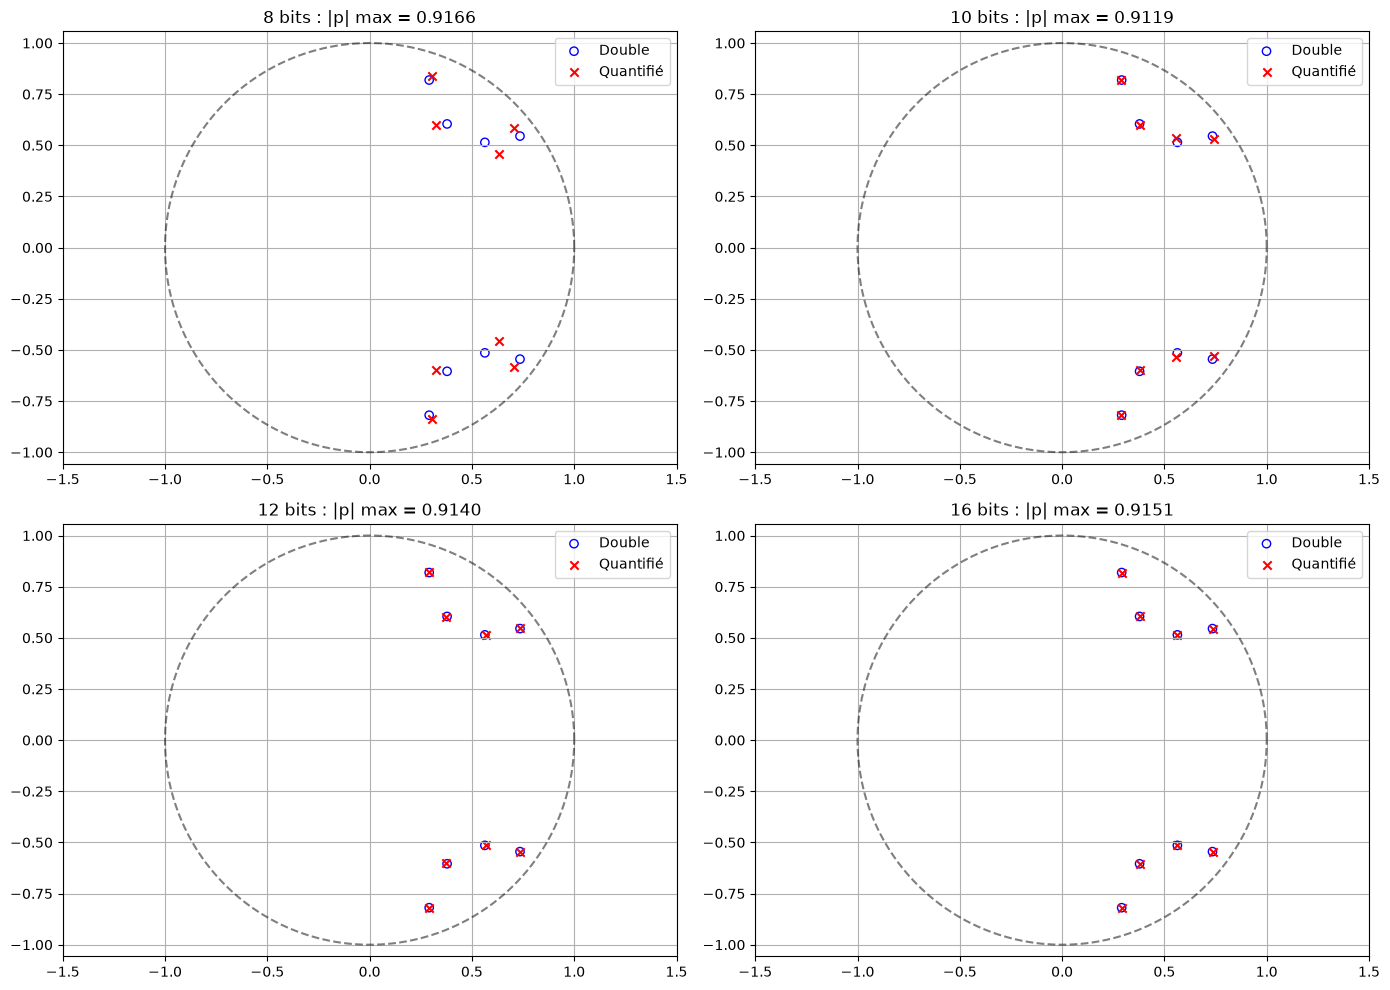

 4 bits : |p| max = 1.2516 -> stable = False
 5 bits : |p| max = 1.0718 -> stable = False
 6 bits : |p| max = 0.8724 -> stable = True
 7 bits : |p| max = 0.9479 -> stable = True
 8 bits : |p| max = 0.9166 -> stable = True
 9 bits : |p| max = 0.9181 -> stable = True
10 bits : |p| max = 0.9119 -> stable = True
11 bits : |p| max = 0.9230 -> stable = True
12 bits : |p| max = 0.9140 -> stable = True
13 bits : |p| max = 0.9164 -> stable = True
14 bits : |p| max = 0.9151 -> stable = True
15 bits : |p| max = 0.9150 -> stable = True
16 bits : |p| max = 0.9151 -> stable = True


In [20]:
# À compléter
# Générer les coefficients quantifiés pour différentes résolutions
# Tracer les réponses et les pôles

fs = 1000
b, a = signal.butter(4, [100, 200], fs=fs, btype='bandpass')
print("Pôles non quantifiés : |p| max =", np.max(np.abs(np.roots(a))))

w, H = signal.freqz(b, a, worN=2048)
freqs = w * fs / (2*np.pi)
theta = np.linspace(0, 2*np.pi, 200)

plt.figure(figsize=(14, 5))
plt.plot(freqs, 20*np.log10(np.abs(H)), 'k', linewidth=2, label='Précision double')
for n_bits in (8, 10, 12, 16):
    b_q = quantize_coeffs(b, n_bits=n_bits)
    a_q = quantize_coeffs(a, n_bits=n_bits)
    _, H_q = signal.freqz(b_q, a_q, worN=2048)
    plt.plot(freqs, 20*np.log10(np.abs(H_q) + 1e-12), '--', label=f'{n_bits} bits')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 500)
plt.ylim(-80, 5)
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(14, 10))
for i, n_bits in enumerate((8, 10, 12, 16)):
    b_q = quantize_coeffs(b, n_bits=n_bits)
    a_q = quantize_coeffs(a, n_bits=n_bits)
    poles_q = np.roots(a_q)
    plt.subplot(2, 2, i+1)
    plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
    plt.scatter(np.real(np.roots(a)), np.imag(np.roots(a)), marker='o', facecolors='none', edgecolors='b', label='Double')
    plt.scatter(np.real(poles_q), np.imag(poles_q), marker='x', color='r', label='Quantifié')
    plt.axis('equal')
    plt.xlim([-1.5, 1.5])
    plt.ylim([-1.5, 1.5])
    plt.title(f'{n_bits} bits : |p| max = {np.max(np.abs(poles_q)):.4f}')
    plt.legend()
    plt.grid()
plt.tight_layout()
plt.show()

for n_bits in range(4, 17):
    a_q = quantize_coeffs(a, n_bits=n_bits)
    p_max = np.max(np.abs(np.roots(a_q)))
    print(f"{n_bits:2d} bits : |p| max = {p_max:.4f} -> stable = {p_max < 1}")

reponse

**Question 1**

Le filtre Butterworth passe-bande d'ordre 4 (bande 100–200 Hz, $f_s = 1000$ Hz) a 9 coefficients au numérateur et au dénominateur (ordre global 8, soit 8 pôles). Ses coefficients sont quantifiés avec `quantize_coeffs` sur 8, 10, 12 et 16 bits. Les pôles non quantifiés ont un module maximal de ≈ 0.915.

**Question 2**

Plus le nombre de bits diminue, plus la réponse en gain s'écarte de celle en précision double :
- **16 bits** : courbe quasiment identique (écart < 0.01 dB dans la bande) ;
- **12 bits** : léger écart (≈ 0.4 dB dans la bande passante) ;
- **10 bits** : écart de ≈ 1.1 dB, avec une rejection hors bande modifiée ;
- **8 bits** : écart de ≈ 2.3 dB dans la bande, déplacement du pic de résonance et mauvaise réjection (gain à 50 Hz ≈ -17.6 dB au lieu de ≈ -41.6 dB).

**Question 3**

La quantification déplace les pôles : leur module maximal vaut ≈ 0.915 sans quantification, 0.915 à 16 bits, 0.914 à 12 bits, 0.912 à 10 bits et 0.917 à 8 bits. En descendant plus bas, les pôles sortent du cercle unité : 5 bits donnent $|p|_{max} \approx 1.07$ et 4 bits $\approx 1.25$ (filtre **instable**). Pour ce filtre, la stabilité est conservée à partir de **6 bits**. Mais la réponse est déjà fortement déformée à 6 et 7 bits (écart de 6 à 10 dB dans la bande), donc en pratique il faut au moins 10 à 12 bits pour une réponse acceptable (ou utiliser la forme en cascade, moins sensible).

## Exercice 5 – Mise en œuvre d'un filtre adaptatif simple (LMS) – Introduction

Un filtre adaptatif permet d'ajuster ses coefficients pour minimiser une erreur. Implémenter un filtre RIF adaptatif utilisant l'algorithme LMS (Least Mean Squares) pour annuler un écho. On donne un signal désiré $d[n]$ et un signal d'entrée $x[n]$ corrélé avec l'écho.

1. Générer un signal $x[n]$ aléatoire.
2. Créer un signal écho : $y[n] = 0.8 x[n-10] + bruit$.
3. Utiliser un filtre RIF de longueur 20 pour estimer la réponse de l'écho.
4. Appliquer l'algorithme LMS (pas = 0.01) pour mettre à jour les coefficients.
5. Afficher l'erreur en fonction des itérations et les coefficients convergés.

**Code** :

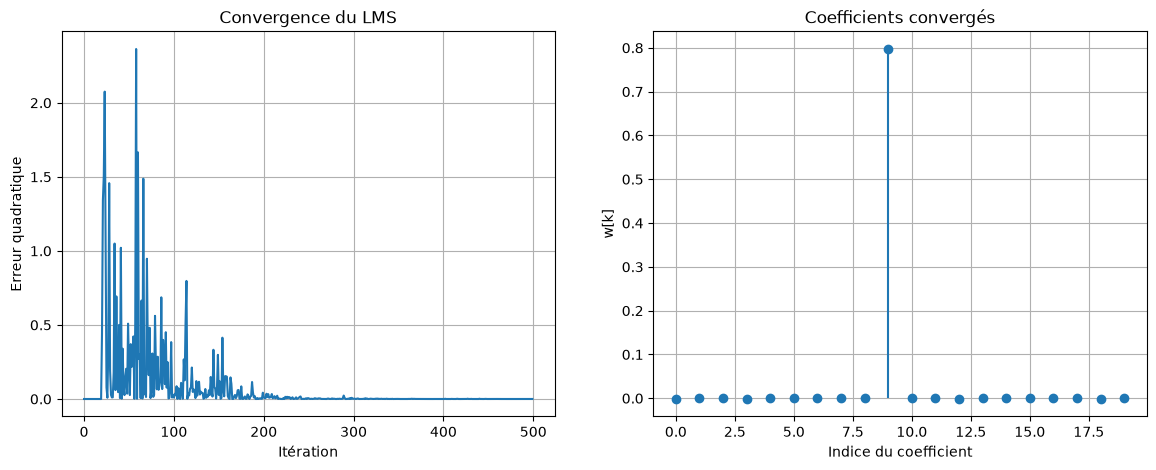

Indice du coefficient maximal : 9
Valeur du coefficient maximal : 0.7973677919892393
Erreur quadratique moyenne (50 premières itérations) : 0.44921592069640076
Erreur quadratique moyenne (50 dernières itérations) : 0.0001204966358436531


In [21]:
# Implémentation LMS
def lms_filter(x, d, M, mu):
    N = len(x)
    w = np.zeros(M)
    y = np.zeros(N)
    e = np.zeros(N)
    for n in range(M, N):
        x_n = x[n-M:n][::-1]  # inversion pour convolution
        y[n] = np.dot(w, x_n)
        e[n] = d[n] - y[n]
        w = w + mu * e[n] * x_n
    return y, e, w

# Test
# Génération des signaux
# x = np.random.randn(500)
# d = ... (signal désiré)
# mu = 0.01
# y, e, w = lms_filter(x, d, 20, mu)
# Tracer l'erreur

x = np.random.randn(500)
d = np.zeros(500)
d[10:] = 0.8 * x[:-10]
d = d + 0.01 * np.random.randn(500)
mu = 0.01
y, e, w = lms_filter(x, d, 20, mu)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(e**2)
plt.xlabel('Itération')
plt.ylabel('Erreur quadratique')
plt.title('Convergence du LMS')
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(np.arange(20), w, basefmt=' ')
plt.xlabel('Indice du coefficient')
plt.ylabel('w[k]')
plt.title('Coefficients convergés')
plt.grid()
plt.show()

print("Indice du coefficient maximal :", np.argmax(np.abs(w)))
print("Valeur du coefficient maximal :", w[np.argmax(np.abs(w))])
print("Erreur quadratique moyenne (50 premières itérations) :", np.mean(e[20:70]**2))
print("Erreur quadratique moyenne (50 dernières itérations) :", np.mean(e[-50:]**2))

reponse

**Question 1**

Le signal d'entrée $x[n]$ est un bruit blanc gaussien de 500 échantillons (`np.random.randn(500)`).

**Question 2**

Le signal d'écho (signal désiré) est $d[n] = 0.8\,x[n-10] + \text{bruit}$, c'est-à-dire l'entrée retardée de 10 échantillons, atténuée par 0.8, avec un bruit gaussien de faible variance (écart-type 0.01).

**Question 3**

On utilise un filtre RIF adaptatif de longueur $M = 20$. Il doit apprendre la réponse impulsionnelle de l'écho, c'est-à-dire un seul coefficient non nul (0.8) au retard de 10.

**Question 4**

L'algorithme LMS met à jour les coefficients à chaque itération :
$$ e[n] = d[n] - \mathbf{w}^T \mathbf{x}_n, \qquad \mathbf{w} \leftarrow \mathbf{w} + \mu\, e[n]\, \mathbf{x}_n, \qquad \mu = 0.01 $$
Le pas $\mu$ doit rester inférieur à $2/(M\sigma_x^2) = 0.1$ pour que l'algorithme converge : $\mu = 0.01$ convient.

**Question 5**

- **Erreur** : l'erreur quadratique est grande au début (≈ 0.4 en moyenne sur les premières itérations, car le filtre vaut 0 et n'annule rien), puis décroît rapidement et converge en environ 150 à 200 itérations vers une valeur très faible (≈ $10^{-4}$), qui correspond à la variance du bruit ajouté ($0.01^2$).
- **Coefficients convergés** : tous les coefficients tendent vers 0 sauf un, qui tend vers ≈ 0.8. Comme le code du prof construit le vecteur d'entrée à partir de $x[n-1]$ (`x[n-M:n][::-1]`), le retard de 10 échantillons correspond à l'indice **9** du vecteur $w$ : $w[9] \approx 0.79$ à $0.80$.

Le filtre adaptatif a donc retrouvé les caractéristiques de l'écho (retard de 10 échantillons et gain de 0.8), ce qui permet de l'annuler en soustrayant sa sortie du signal désiré.

# 5. Livrable Semaine 10

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---